<a href="https://colab.research.google.com/github/tharunikaravi028/SolarScope_AI/blob/main/SolarScope_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q openai sentence-transformers faiss-cpu rank_bm25 pypdf pandas matplotlib gradio

In [4]:
from google.colab import userdata
from openai import OpenAI

client = OpenAI(api_key=userdata.get("API_KEY"), base_url=userdata.get("BASE_URL"))

models = client.models.list()
for m in models.data:
    print(m.id)

nano-banana
whisper-1
nova-micro
text-embedding-3-small
gpt-4o-mini-tts
gpt-4.1-nano


In [5]:
MODEL = "gpt-4.1-nano"

r = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "Explain solar panel degradation in one sentence."}]
)
print(r.choices[0].message.content)

NotFoundError: Error code: 404 - {'error': {'message': 'litellm.NotFoundError: OpenAIException - The model `gpt-4.1-nano` has been deprecated, learn more here: https://platform.openai.com/docs/deprecations. Received Model Group=gpt-4.1-nano\nAvailable Model Group Fallbacks=None', 'type': 'invalid_request_error', 'param': None, 'code': '404'}}

In [7]:
MODEL = "nova-micro"
EMBED_MODEL = "text-embedding-3-small"
print("Chat model:", MODEL)

Chat model: nova-micro


In [6]:
test_models = ["nova-micro", "gpt-4.1-nano", "nano-banana"]

for m in test_models:
    try:
        r = client.chat.completions.create(
            model=m,
            messages=[{"role": "user", "content": "Explain solar panel degradation in one sentence."}],
            max_tokens=60
        )
        print("WORKS:", m, "->", r.choices[0].message.content)
    except Exception as e:
        print("FAILED:", m, "->", str(e)[:120])

WORKS: nova-micro -> Solar panel degradation refers to the gradual decline in the efficiency and output of photovoltaic cells over time due to factors such as environmental exposure, manufacturing defects, and natural material wear.
FAILED: gpt-4.1-nano -> Error code: 404 - {'error': {'message': 'litellm.NotFoundError: OpenAIException - The model `gpt-4.1-nano` has been depr
FAILED: nano-banana -> Error code: 402 - {'error': {'message': 'litellm.BadRequestError: GeminiException - {\n  "error": {\n    "code": 402,\n 


In [8]:
e = client.embeddings.create(model=EMBED_MODEL, input=["solar panel overheating"])
print(len(e.data[0].embedding))

1536


In [10]:
import os
os.makedirs("/content/docs", exist_ok=True)
print("Folder ready")

Folder ready


In [11]:
docs = {
"pv_degradation_guide.txt": """Solar panel degradation guide.
Photovoltaic modules lose output gradually over their life. A typical long-term degradation rate for crystalline silicon panels is about 0.5 percent per year, and a rate above roughly 1 percent per year suggests a problem.
Common causes of faster degradation: potential induced degradation (PID), light induced degradation in the first months, encapsulant browning, delamination, corrosion of cell contacts, and microcracks in cells.
A sudden drop in power output is usually not normal ageing. It points to a fault such as a failed bypass diode, a broken connector, a cracked module, or a string failure. Inspect the module and the string wiring first.""",

"overheating_and_hotspots.txt": """Overheating and hot spots in solar panels.
Panel output falls as cell temperature rises. Most crystalline silicon modules have a temperature coefficient of power between minus 0.3 and minus 0.5 percent per degree Celsius above 25 degrees Celsius. A panel at 65 degrees Celsius can lose around 12 to 20 percent of its rated power from heat alone.
Hot spots happen when a cell or group of cells dissipates power as heat, usually because of partial shading, cell mismatch, cracked cells, or a failed bypass diode. Local temperatures can rise far above the rest of the module and damage the encapsulant.
Detection: infrared thermography shows hot spots clearly. A temperature difference of more than 10 to 20 degrees Celsius between cells in the same module needs attention.
Prevention: keep ventilation gaps behind the panels, remove shading from vegetation or objects, replace damaged modules, and check bypass diodes during maintenance.""",

"dust_soiling_maintenance.txt": """Dust and soiling losses.
Dust, pollen, bird droppings, and sand settle on the glass and block sunlight. Soiling typically causes a few percent energy loss in normal conditions, and much more in dry, dusty regions or near construction and farmland, especially when there is no rain for weeks.
Signs of soiling: output declines slowly over days or weeks while irradiance stays similar, and performance recovers after rain or cleaning.
Cleaning guidance: clean early in the morning or in the evening when panels are cool. Use soft brushes or low pressure water. Avoid abrasive tools and cold water on very hot glass. Do not walk on panels.
Cleaning frequency should depend on measured losses. Track the performance ratio and schedule cleaning when the drop from soiling becomes larger than the cost of cleaning.""",

"inspection_and_maintenance_checklist.txt": """Routine inspection and maintenance checklist for solar plants.
Monthly: visual check for dirt, cracks, discoloured cells, snail trails, and loose frames. Check that no shade has appeared from new vegetation or structures.
Quarterly: inspect cabling, connectors, and junction boxes for corrosion, heat marks, or loose connections. Compare string currents to find underperforming strings.
Yearly: infrared thermography scan, insulation resistance test, inverter check, and mounting structure inspection.
Monitoring: calculate the performance ratio, which is actual energy output divided by the expected energy from irradiance. A steady performance ratio between about 75 and 85 percent is healthy. A fall of more than 5 to 10 percent from the normal baseline should trigger an inspection.
Record all findings in a maintenance log so that degradation trends can be tracked over the years."""
}

for name, text in docs.items():
    with open(f"/content/docs/{name}", "w") as f:
        f.write(text)

print(os.listdir("/content/docs"))

['dust_soiling_maintenance.txt', 'inspection_and_maintenance_checklist.txt', 'overheating_and_hotspots.txt', 'pv_degradation_guide.txt']


In [12]:
import glob, numpy as np
from pypdf import PdfReader

def load_docs(folder="/content/docs"):
    out = []
    for f in glob.glob(folder + "/*"):
        name = os.path.basename(f)
        if f.endswith(".pdf"):
            for i, p in enumerate(PdfReader(f).pages):
                out.append((name, i + 1, p.extract_text() or ""))
        elif f.endswith(".txt"):
            out.append((name, 1, open(f).read()))
    return out

def chunk(text, size=800, overlap=150):
    return [text[i:i+size] for i in range(0, len(text), size - overlap) if text[i:i+size].strip()]

chunks = []
for src, page, text in load_docs():
    for c in chunk(text):
        chunks.append({"text": c, "source": src, "page": page})
print("Total chunks:", len(chunks))

vectors = []
for i in range(0, len(chunks), 50):
    batch = [c["text"] for c in chunks[i:i+50]]
    res = client.embeddings.create(model=EMBED_MODEL, input=batch)
    vectors += [d.embedding for d in res.data]

emb = np.array(vectors, dtype="float32")
emb = emb / np.linalg.norm(emb, axis=1, keepdims=True)
print("Embeddings shape:", emb.shape)

Total chunks: 8
Embeddings shape: (8, 1536)


In [13]:
from rank_bm25 import BM25Okapi

bm25 = BM25Okapi([c["text"].lower().split() for c in chunks])

def rewrite_query(q):
    r = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": "Rewrite the user's question as 3 short search queries for solar panel technical documents. Output one query per line, no numbering."},
            {"role": "user", "content": q}
        ],
        max_tokens=100
    )
    lines = [x.strip("-• ").strip() for x in r.choices[0].message.content.split("\n") if x.strip()]
    return lines[:3] + [q]

def hybrid_retrieve(q, k=4):
    scores = {}
    for query in rewrite_query(q):
        # semantic search
        qe = np.array(client.embeddings.create(model=EMBED_MODEL, input=[query]).data[0].embedding, dtype="float32")
        qe = qe / np.linalg.norm(qe)
        sem = emb @ qe
        for rank, i in enumerate(np.argsort(sem)[::-1][:6]):
            scores[i] = scores.get(i, 0) + 1 / (60 + rank)
        # keyword search
        kw = bm25.get_scores(query.lower().split())
        for rank, i in enumerate(np.argsort(kw)[::-1][:6]):
            scores[i] = scores.get(i, 0) + 1 / (60 + rank)
    top = sorted(scores, key=scores.get, reverse=True)[:k]
    return [chunks[i] for i in top]

# Test
results = hybrid_retrieve("Why is my panel output dropping slowly over weeks?")
for r in results:
    print("SOURCE:", r["source"])
    print(r["text"][:200], "\n")

SOURCE: pv_degradation_guide.txt
Solar panel degradation guide.
Photovoltaic modules lose output gradually over their life. A typical long-term degradation rate for crystalline silicon panels is about 0.5 percent per year, and a rate 

SOURCE: overheating_and_hotspots.txt
Overheating and hot spots in solar panels.
Panel output falls as cell temperature rises. Most crystalline silicon modules have a temperature coefficient of power between minus 0.3 and minus 0.5 percen 

SOURCE: dust_soiling_maintenance.txt
Dust and soiling losses.
Dust, pollen, bird droppings, and sand settle on the glass and block sunlight. Soiling typically causes a few percent energy loss in normal conditions, and much more in dry, d 

SOURCE: inspection_and_maintenance_checklist.txt
Routine inspection and maintenance checklist for solar plants.
Monthly: visual check for dirt, cracks, discoloured cells, snail trails, and loose frames. Check that no shade has appeared from new vege 



In [14]:
import pandas as pd, numpy as np

np.random.seed(42)
n = 120
dates = pd.date_range("2026-07-01", periods=n)
irr = np.random.uniform(5, 7, n)                      # daily irradiance
temp = 40 + (irr - 5) * 5 + np.random.normal(0, 2, n)  # panel temperature
temp[80:86] += 25                                      # overheating period

health = np.ones(n)
health[40:70] = np.linspace(1, 0.85, 30)               # slow dust build-up
health[70:100] = 0.85
health[100:] = 0.60                                    # sudden damage

power = irr * 20 * (1 - 0.004 * (temp - 25)) * health + np.random.normal(0, 0.3, n)

df = pd.DataFrame({"date": dates, "irradiance": irr.round(2),
                   "panel_temp": temp.round(1), "power_output": power.round(2)})
df.to_csv("/content/solar_data.csv", index=False)
df.head()

,date,irradiance,panel_temp,power_output
0,2026-07-01,5.75,42.3,107.29
1,2026-07-02,6.90,48.9,125.06
2,2026-07-03,6.46,46.5,118.05
3,2026-07-04,6.20,43.1,115.22
4,2026-07-05,5.31,42.2,98.72


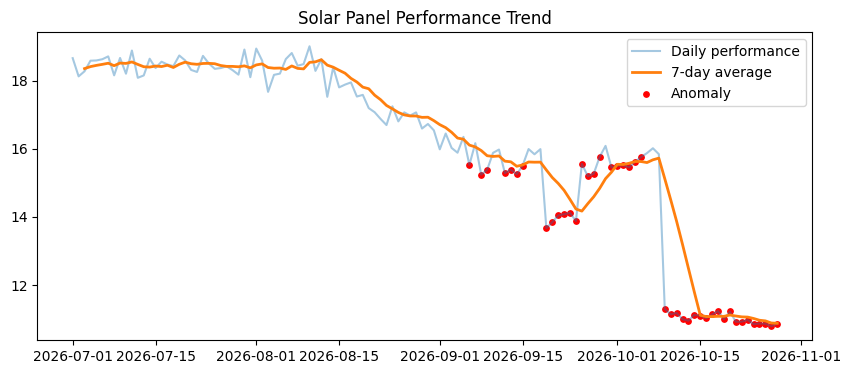

- 43 days with performance more than 15% below baseline
- Panel temperature above 65C on 6 days (2026-09-19 to 2026-09-24): possible overheating
- Sudden performance drop of 29% on 2026-10-09: possible panel or wiring damage
- Overall performance is 41% below the initial baseline: possible dust accumulation or degradation


In [15]:
import matplotlib.pyplot as plt

def analyze(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df["pr"] = df["power_output"] / df["irradiance"]          # performance ratio proxy
    df["pr_roll"] = df["pr"].rolling(7, min_periods=3).mean()

    baseline = df["pr"].iloc[:20].median()
    df["anomaly"] = df["pr"] < baseline * 0.85
    findings = []

    n_anom = int(df["anomaly"].sum())
    if n_anom:
        findings.append(f"{n_anom} days with performance more than 15% below baseline")

    hot = df["panel_temp"] > 65
    if hot.sum() >= 2:
        findings.append(f"Panel temperature above 65C on {int(hot.sum())} days "
                        f"({df[hot]['date'].iloc[0].date()} to {df[hot]['date'].iloc[-1].date()}): possible overheating")

    prev_avg = df["pr"].rolling(5).mean().shift(1)
    change = df["pr"] / prev_avg - 1
    if change.min() < -0.2:
        d = df.loc[change.idxmin(), "date"].date()
        findings.append(f"Sudden performance drop of {abs(change.min()):.0%} on {d}: possible panel or wiring damage")

    decline = 1 - df["pr"].iloc[-14:].mean() / baseline
    if decline > 0.05:
        findings.append(f"Overall performance is {decline:.0%} below the initial baseline: possible dust accumulation or degradation")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(df["date"], df["pr"], alpha=0.4, label="Daily performance")
    ax.plot(df["date"], df["pr_roll"], linewidth=2, label="7-day average")
    ax.scatter(df[df.anomaly]["date"], df[df.anomaly]["pr"], c="red", s=15, label="Anomaly")
    ax.set_title("Solar Panel Performance Trend"); ax.legend()
    fig.savefig("/content/trend.png", bbox_inches="tight")
    plt.show()
    return df, findings

df = pd.read_csv("/content/solar_data.csv")
result_df, findings = analyze(df)
for f in findings:
    print("-", f)

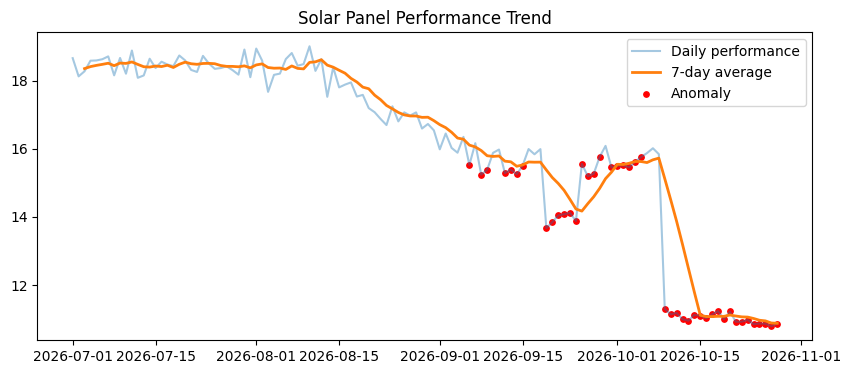

## Solar Panel Operations and Maintenance Report

### 1. Performance Summary

The solar panel array has exhibited significant performance issues over the recent period. The overall performance stands at 41% below the initial baseline. Specific anomalies detected include:

- 43 days with performance more than 15% below baseline.
- Panel temperatures exceeding 65°C on 6 days (2026-09-19 to 2026-09-24), indicating possible overheating.
- A sudden performance drop of 29% on 2026-10-09, suggesting potential panel or wiring damage.
- Visible dust accumulation on the panel surface.
- One junction box appeared discoloured during inspection.

### 2. Detected Issues

#### Performance Drops

1. **43 Days of Below Baseline Performance**
   - Performance fell more than 15% below the baseline for 43 days.
   - Indicates potential issues such as dust accumulation or degradation.

2. **Overheating Events**
   - Panel temperatures above 65°C on 6 days.
   - Possible hot spots could have formed, reducin

In [16]:
def generate_report(df, inspection_notes=""):
    df, findings = analyze(df)

    # Retrieve supporting documents for each finding
    refs, seen = [], set()
    for f in findings:
        for c in hybrid_retrieve(f + " causes and maintenance", k=2):
            key = (c["source"], c["text"][:50])
            if key not in seen:
                seen.add(key)
                refs.append(c)

    context = "\n\n".join(f"[{c['source']}] {c['text']}" for c in refs[:6])
    stats = (f"Average irradiance: {df['irradiance'].mean():.2f}, "
             f"average panel temperature: {df['panel_temp'].mean():.1f}C, "
             f"max panel temperature: {df['panel_temp'].max():.1f}C, "
             f"average power output: {df['power_output'].mean():.2f}")

    prompt = f"""You are a solar panel operations and maintenance expert.
Write a detailed report with these sections:
1. Performance Summary
2. Detected Issues
3. Possible Causes
4. Maintenance Suggestions
5. References

Rules: use ONLY the context below for technical claims, and cite sources like [filename].
In the References section, list the source file names you used.

Detected findings:
{chr(10).join('- ' + f for f in findings)}

Data statistics: {stats}
Inspection notes: {inspection_notes or 'None provided'}

Context from technical documents:
{context}"""

    r = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": prompt}],
        max_tokens=1200
    )
    return r.choices[0].message.content

df = pd.read_csv("/content/solar_data.csv")
report = generate_report(df, "Visible dust on panel surface. One junction box looked discoloured.")
print(report)

In [18]:
import gradio as gr

def run_app(csv_file, notes):
    if csv_file is None:
        return None, "Please upload a CSV file first."
    path = csv_file if isinstance(csv_file, str) else csv_file.name
    try:
        data = pd.read_csv(path)
        needed = {"date", "irradiance", "panel_temp", "power_output"}
        if not needed.issubset(data.columns):
            return None, f"CSV must contain these columns: {sorted(needed)}"
        report = generate_report(data, notes or "")
        return "/content/trend.png", report
    except Exception as e:
        return None, f"Error: {e}"

app = gr.Interface(
    fn=run_app,
    inputs=[
        gr.File(label="Upload performance CSV (date, irradiance, panel_temp, power_output)"),
        gr.Textbox(label="Inspection notes (optional)", lines=4,
                   placeholder="e.g. Visible dust on panels, discoloured junction box")
    ],
    outputs=[
        gr.Image(label="Performance trend"),
        gr.Markdown(label="Generated report")
    ],
    title="SolarScope AI",
    description="Solar panel performance monitoring and degradation analysis using Advanced RAG"
)

app.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ca0b05d412c132a613.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://ca0b05d412c132a613.gradio.live


In [19]:
import gradio as gr

def full_analysis(csv_file, notes):
    if csv_file is None:
        return "Please upload a CSV file.", None, "", "", "", None
    path = csv_file if isinstance(csv_file, str) else csv_file.name
    try:
        data = pd.read_csv(path)
        needed = {"date", "irradiance", "panel_temp", "power_output"}
        if not needed.issubset(data.columns):
            return f"CSV must contain: {sorted(needed)}", None, "", "", "", None

        d, findings = analyze(data)
        baseline = d["pr"].iloc[:20].median()
        decline = 1 - d["pr"].iloc[-14:].mean() / baseline
        status = "🔴 CRITICAL" if decline > 0.25 else "🟡 WARNING" if decline > 0.10 else "🟢 HEALTHY"

        status_md = (f"## System status: {status}\n\n"
                     f"| Metric | Value |\n|---|---|\n"
                     f"| Performance vs baseline | -{decline:.0%} |\n"
                     f"| Anomalous days | {int(d['anomaly'].sum())} of {len(d)} |\n"
                     f"| Max panel temperature | {d['panel_temp'].max():.1f} °C |\n"
                     f"| Average irradiance | {d['irradiance'].mean():.2f} |")

        findings_md = "\n".join(f"- {f}" for f in findings) or "- No significant issues detected."

        evidence = hybrid_retrieve(" ".join(findings) or "normal solar performance", k=4)
        evidence_md = "\n\n".join(f"**Source: {c['source']}** (page {c['page']})\n\n> {c['text'][:350]}..." for c in evidence)

        report = generate_report(data, notes or "")
        with open("/content/solarscope_report.md", "w") as f:
            f.write(f"# SolarScope AI Report\n\n{status_md}\n\n## Findings\n{findings_md}\n\n{report}")

        return status_md, "/content/trend.png", findings_md, evidence_md, report, "/content/solarscope_report.md"
    except Exception as e:
        return f"Error: {e}", None, "", "", "", None

with gr.Blocks(title="SolarScope AI") as app:
    gr.Markdown("# ☀️ SolarScope AI\nIntelligent solar panel performance monitoring and degradation analysis using Advanced RAG")
    with gr.Row():
        with gr.Column(scale=1):
            f_in = gr.File(label="Performance CSV (date, irradiance, panel_temp, power_output)", file_types=[".csv"])
            notes_in = gr.Textbox(label="Inspection notes (optional)", lines=4,
                                  placeholder="e.g. Visible dust on panels, discoloured junction box")
            btn = gr.Button("Analyze", variant="primary")
        with gr.Column(scale=2):
            status_out = gr.Markdown()
            chart_out = gr.Image(label="Performance trend")
    with gr.Tabs():
        with gr.Tab("AI Report"):
            report_out = gr.Markdown()
        with gr.Tab("Detected Findings"):
            findings_out = gr.Markdown()
        with gr.Tab("Retrieved Evidence (RAG)"):
            evidence_out = gr.Markdown()
    dl = gr.File(label="Download report")
    btn.click(full_analysis, [f_in, notes_in], [status_out, chart_out, findings_out, evidence_out, report_out, dl])

app.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://427471acc75540cffc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
